In [1]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
# Step 1: Load Dataset
data = fetch_california_housing()
X = data.data[:, [0]]  # Median income
y = data.target

In [3]:
# Step 2: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [4]:
# Step 3: Linear Regression
linear = LinearRegression()
linear.fit(X_train, y_train)
y_pred1 = linear.predict(X_test)

In [5]:
# Step 4: Polynomial Regression
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [6]:
model = LinearRegression()
model.fit(X_train_poly, y_train)
y_pred2 = model.predict(X_test_poly)

In [7]:
# Step 5: Evaluate Models
for name, pred in [
    ("Linear Regression", y_pred1),
    ("Polynomial Regression", y_pred2)
]:
    print("\n", name)
    print("MSE:", mean_squared_error(y_test, pred))
    print("MAE:", mean_absolute_error(y_test, pred))
    print("R2 Score:", r2_score(y_test, pred))


 Linear Regression
MSE: 0.7091157771765549
MAE: 0.629908653009376
R2 Score: 0.45885918903846656

 Polynomial Regression
MSE: 0.7032732680932144
MAE: 0.6282915588701903
R2 Score: 0.46331772769346224


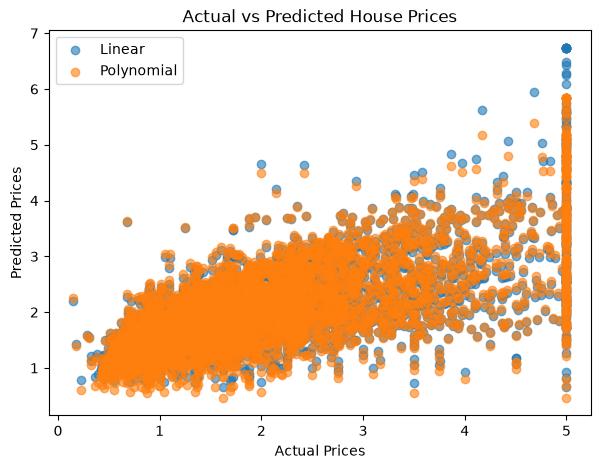

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred1, label='Linear', alpha=0.6)
plt.scatter(y_test, y_pred2, label='Polynomial', alpha=0.6)

plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.show()

